# 09. Executed Extensions, Visual Evidence, and Conclusions

This notebook reruns the optional extensions on the real MUSAE GitHub data and creates every displayed chart from executable plotting code below. Extension results and artifacts remain separate from the core findings in notebooks 01-08 and do not alter the final report.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import Markdown, display


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'requirements.txt').exists() and (candidate / 'data').exists():
            return candidate.resolve()
    raise FileNotFoundError('Could not locate the project root.')


ROOT = find_project_root(Path.cwd())
os.chdir(ROOT)
for code_dir in (ROOT / 'src', ROOT / 'extensions'):
    if str(code_dir) not in sys.path:
        sys.path.insert(0, str(code_dir))

os.environ['PYTHONHASHSEED'] = '0'
warnings.filterwarnings('ignore', category=FutureWarning)
OUTPUT_ROOT = ROOT / 'outputs' / 'extensions'
TABLES = OUTPUT_ROOT / 'tables'
FIGURES = OUTPUT_ROOT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEEDS = (42, 7, 21, 84, 123)
METRICS = ('roc_auc', 'macro_f1', 'f1', 'balanced_accuracy', 'precision', 'recall')
MODEL_ORDER = [
    'Label Propagation', 'GCN', 'GraphSAGE',
    'Logistic Regression - Hybrid (Network + Content)',
    'Logistic Regression - DeepWalk + Graph + Community',
]
DISPLAY_NAMES = {
    'Label Propagation': 'Label Propagation',
    'GCN': 'GCN',
    'GraphSAGE': 'GraphSAGE',
    'Logistic Regression - Hybrid (Network + Content)': 'Core Hybrid',
    'Logistic Regression - DeepWalk + Graph + Community': 'DeepWalk + Graph + Community',
}
MODEL_COLORS = {
    'Label Propagation': '#F28E2B', 'GCN': '#59A14F', 'GraphSAGE': '#B07AA1',
    'Logistic Regression - Hybrid (Network + Content)': '#7A7A7A',
    'Logistic Regression - DeepWalk + Graph + Community': '#4E79A7',
}
sns.set_theme(style='whitegrid', context='notebook')


def save_show(fig, filename: str) -> None:
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=200, bbox_inches='tight')
    plt.show()


print(f'Project root: {ROOT}')
print(f'Python: {sys.version.split()[0]} | PyTorch: {torch.__version__} | device: CPU')

Project root: C:\Users\Jimi\Desktop\github-social-network
Python: 3.11.9 | PyTorch: 2.5.1+cpu | device: CPU


## Fresh execution and leakage-safe protocol

The next cell reruns Label Propagation, GCN, GraphSAGE, and content clustering from source. It does not reuse cached predictions. All classifiers use the core pipeline's same five fixed stratified 70/30 outer splits. Each outer training set is split 80/20 for parameter and stopping-epoch selection; the chosen setting is then refit with all outer-training labels. Test labels are hidden as `-1` until all final fits for a split finish.

GCN and GraphSAGE are **transductive**: the full graph and label-free node covariates are visible. Scaling is fit only on inner-training nodes during selection and outer-training nodes during final refitting. No unseen-node experiment is performed, so no inductive performance is claimed.

In [2]:
from run_gnn import main as run_classification_extensions
from run_subfields import main as run_subfield_extension

notebook_started = time.perf_counter()
classification_paths = run_classification_extensions()
subfield_paths = run_subfield_extension()
get_ipython().run_line_magic('matplotlib', 'inline')  # runners use Agg for script mode
notebook_runtime = time.perf_counter() - notebook_started
print(f'All extension experiments completed from source in {notebook_runtime:.1f} seconds.')

[extension split 1/5] seed=42


  Label Propagation: Macro-F1=0.7180, ROC-AUC=0.7900
  GCN: Macro-F1=0.7974, ROC-AUC=0.9060
  GraphSAGE: Macro-F1=0.7985, ROC-AUC=0.9060
[extension split 2/5] seed=7


  Label Propagation: Macro-F1=0.7231, ROC-AUC=0.8092
  GCN: Macro-F1=0.8082, ROC-AUC=0.9123
  GraphSAGE: Macro-F1=0.8072, ROC-AUC=0.9111
[extension split 3/5] seed=21


  Label Propagation: Macro-F1=0.7238, ROC-AUC=0.7964
  GCN: Macro-F1=0.8007, ROC-AUC=0.9032
  GraphSAGE: Macro-F1=0.8044, ROC-AUC=0.9034
[extension split 4/5] seed=84


  Label Propagation: Macro-F1=0.7234, ROC-AUC=0.8123
  GCN: Macro-F1=0.8079, ROC-AUC=0.9123
  GraphSAGE: Macro-F1=0.8038, ROC-AUC=0.9121
[extension split 5/5] seed=123


...

  k=7: silhouette=0.0442, stability ARI=0.4943 +/- 0.1544


  k=8: silhouette=0.0466, stability ARI=0.5305 +/- 0.1577


  k=9: silhouette=0.0469, stability ARI=0.6869 +/- 0.0800


  k=10: silhouette=0.0485, stability ARI=0.6183 +/- 0.2003
Selected k=3 by target-free silhouette maximization.


Subfield experiment completed in 40.4s
 cluster  size  ml_count  share_of_nodes  ml_share
       0 13366      3078        0.354536  0.230286
       1 17128      4099        0.454324  0.239316
       2  7206      2562        0.191141  0.355537
                             comparison      nmi      ari
      content_clusters_vs_binary_labels 0.006918 0.018087
content_clusters_vs_louvain_communities 0.007866 0.001919
   louvain_communities_vs_binary_labels 0.106123 0.062276
All extension experiments completed from source in 911.2 seconds.


## Executed results, settings, and leakage audit

These tables are loaded only after the fresh source run above has overwritten them. Assertions make the notebook fail if any partition overlaps or any test label is visible during selection or final fitting.

In [3]:
classification = pd.read_csv(TABLES / 'node_classification_results.csv')
classification_summary = pd.read_csv(TABLES / 'node_classification_summary.csv')
core_results = pd.read_csv(TABLES / 'core_baseline_results_same_splits.csv')
comparison_summary = pd.read_csv(TABLES / 'classification_comparison_summary.csv')
selected_settings = pd.read_csv(TABLES / 'selected_settings.csv')
gnn_history = pd.read_csv(TABLES / 'gnn_training_history.csv')
leakage_audit = pd.read_csv(TABLES / 'leakage_audit.csv')
split_manifest = pd.read_csv(TABLES / 'fixed_split_manifest.csv')
classification_runtime = pd.read_csv(TABLES / 'classification_runtime.csv')
classification_meta = json.loads((TABLES / 'classification_run_metadata.json').read_text())
subfield_meta = json.loads((TABLES / 'subfield_run_metadata.json').read_text())

assert leakage_audit['partitions_disjoint_and_complete'].all()
visibility_columns = [
    'selection_test_labels_visible', 'final_fit_test_labels_visible',
    'lp_selection_test_labels_visible'
]
assert leakage_audit[visibility_columns].to_numpy().sum() == 0
assert set(classification['random_state']) == set(SEEDS)
assert set(gnn_history['model']) == {'GCN', 'GraphSAGE'}

def mean_sd_table(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for _, row in frame.iterrows():
        output = {'Model': DISPLAY_NAMES.get(row['model'], row['model'])}
        for metric in METRICS:
            output[metric] = f"{row[f'{metric}_mean']:.4f} +/- {row[f'{metric}_std']:.4f}"
        rows.append(output)
    return pd.DataFrame(rows)

display(Markdown('**Five-split extension results (mean +/- sample SD)**'))
display(mean_sd_table(classification_summary))
display(Markdown('**All fifteen per-seed extension evaluations**'))
display(classification.round(4))
display(Markdown('**Validation-selected settings and stopping epochs**'))
display(selected_settings[[
    'random_state', 'model', 'alpha', 'iterations', 'hidden', 'dropout',
    'learning_rate', 'weight_decay', 'best_epoch',
    'validation_macro_f1', 'validation_roc_auc'
]].round(4))
display(Markdown('**Leakage audit**'))
display(leakage_audit)
display(Markdown('**Split manifest**'))
display(split_manifest)
display(Markdown('**Measured runtime by method**'))
display(classification_runtime.groupby('model', as_index=False)['seconds'].sum().round(2))

**Five-split extension results (mean +/- sample SD)**

,Model,roc_auc,macro_f1,f1,balanced_accuracy,precision,recall
0,GCN,0.9087 +/- 0.0040,0.8028 +/- 0.0049,0.7208 +/- 0.0070,0.8297 +/- 0.0059,0.6464 +/- 0.0079,0.8148 +/- 0.0132
1,GraphSAGE,0.9083 +/- 0.0036,0.8024 +/- 0.0040,0.7183 +/- 0.0054,0.8252 +/- 0.0047,0.6528 +/- 0.0098,0.7986 +/- 0.0137
2,Label Propagation,0.8025 +/- 0.0092,0.7218 +/- 0.0024,0.5499 +/- 0.0039,0.6907 +/- 0.0020,0.8498 +/- 0.0106,0.4065 +/- 0.0037


**All fifteen per-seed extension evaluations**

,run,random_state,model,roc_auc,macro_f1,f1,balanced_accuracy,precision,recall
0,1,42,Label Propagation,0.7900,0.7180,0.5436,0.6876,0.8404,0.4018
1,1,42,GCN,0.9060,0.7974,0.7141,0.8258,0.6362,0.8138
2,1,42,GraphSAGE,0.9060,0.7985,0.7128,0.8212,0.6477,0.7926
3,2,7,Label Propagation,0.8092,0.7231,0.5528,0.6923,0.8396,0.4120
4,2,7,GCN,0.9123,0.8082,0.7296,0.8381,0.6488,0.8333
5,2,7,GraphSAGE,0.9111,0.8072,0.7257,0.8316,0.6568,0.8107
6,3,21,Label Propagation,0.7964,0.7238,0.5526,0.6920,0.8610,0.4069
7,3,21,GCN,0.9032,0.8007,0.7159,0.8235,0.6504,0.7960
8,3,21,GraphSAGE,0.9034,0.8044,0.7182,0.8212,0.6673,0.7775
9,4,84,Label Propagation,0.8123,0.7234,0.5520,0.6917,0.8608,0.4062


**Validation-selected settings and stopping epochs**

...

,run,random_state,partitions_disjoint_and_complete,selection_test_labels_visible,final_fit_test_labels_visible,lp_selection_test_labels_visible,inner_scaler_fit_nodes,final_scaler_fit_nodes,test_labels_used_only_after_fit
0,1,42,True,0,0,0,21112,26390,True
1,2,7,True,0,0,0,21112,26390,True
2,3,21,True,0,0,0,21112,26390,True
3,4,84,True,0,0,0,21112,26390,True
4,5,123,True,0,0,0,21112,26390,True


**Split manifest**

,run,random_state,inner_train_nodes,validation_nodes,outer_train_nodes,test_nodes,outer_train_digest,test_digest
0,1,42,21112,5278,26390,11310,901e2273b793609e,93b14f7db4784dce
1,2,7,21112,5278,26390,11310,c6826996cff82988,714016ad161d9537
2,3,21,21112,5278,26390,11310,4c6ba09002c02a68,2d66107c71198357
3,4,84,21112,5278,26390,11310,d2db37670c2aa77c,2a9e1ca7322a54d7
4,5,123,21112,5278,26390,11310,c49288baa3b9c39d,4cf665618b807a88


**Measured runtime by method**

,model,seconds
0,GCN,536.46
1,GraphSAGE,310.58
2,Label Propagation,4.79


## Experiment 1 - Label Propagation

Label Propagation repeatedly mixes row-normalized neighbor scores with the visible training-label prior, then reclamps training nodes. Validation tested `alpha` in `{0.60, 0.80, 0.90, 0.99}` and stopping points in `{5, 10, 25, 50, 100}`. Validation and test labels were never propagated.

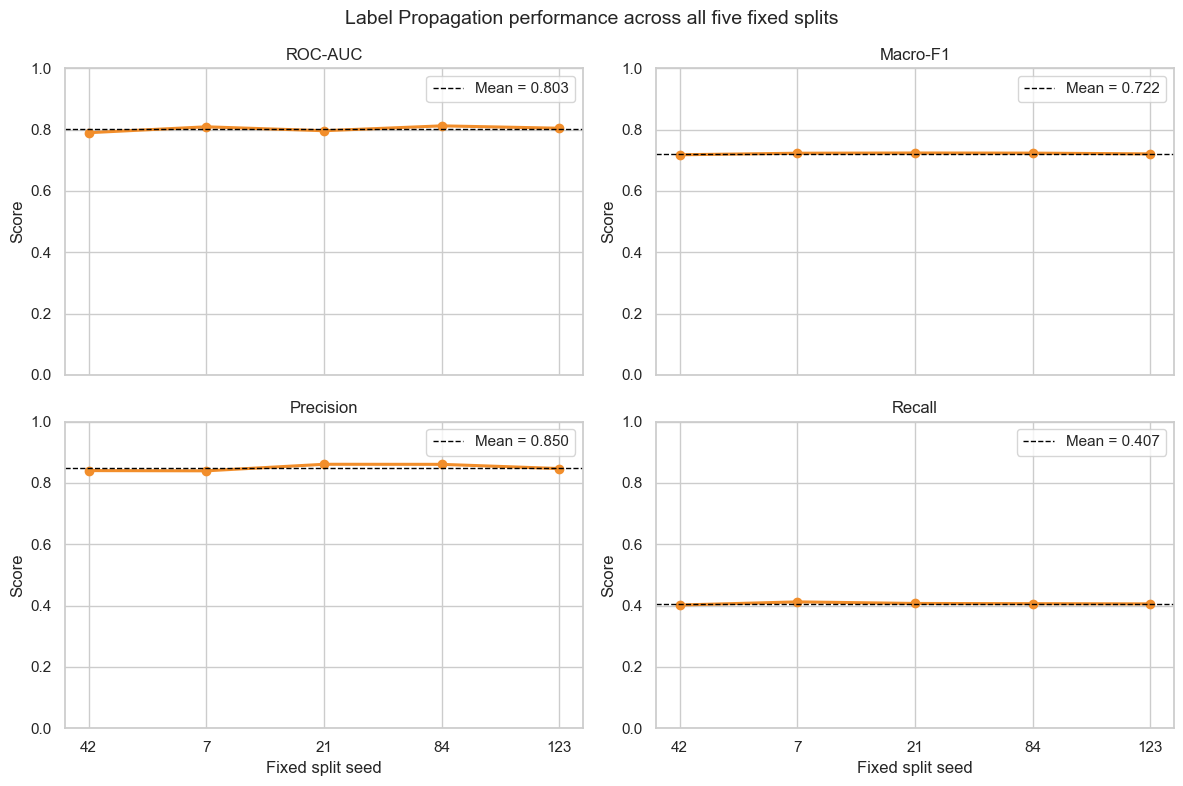

In [4]:
lp = classification.query("model == 'Label Propagation'").copy()
lp['seed_label'] = lp['random_state'].astype(str)
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, metric, title in zip(
    axes.ravel(),
    ['roc_auc', 'macro_f1', 'precision', 'recall'],
    ['ROC-AUC', 'Macro-F1', 'Precision', 'Recall'],
):
    ax.plot(lp['seed_label'], lp[metric], marker='o', linewidth=2.2, color=MODEL_COLORS['Label Propagation'])
    ax.axhline(lp[metric].mean(), color='black', linestyle='--', linewidth=1, label=f"Mean = {lp[metric].mean():.3f}")
    ax.set_title(title)
    ax.set_ylabel('Score')
    ax.set_ylim(0, 1)
    ax.legend(loc='best')
for ax in axes[1]:
    ax.set_xlabel('Fixed split seed')
fig.suptitle('Label Propagation performance across all five fixed splits', fontsize=14)
save_show(fig, 'label_propagation_metrics_by_seed.png')

The four scores change little across seeds. ROC-AUC stays between 0.790 and 0.812 and Macro-F1 stays near 0.72, so the weaker result is consistent rather than caused by one unusual split.

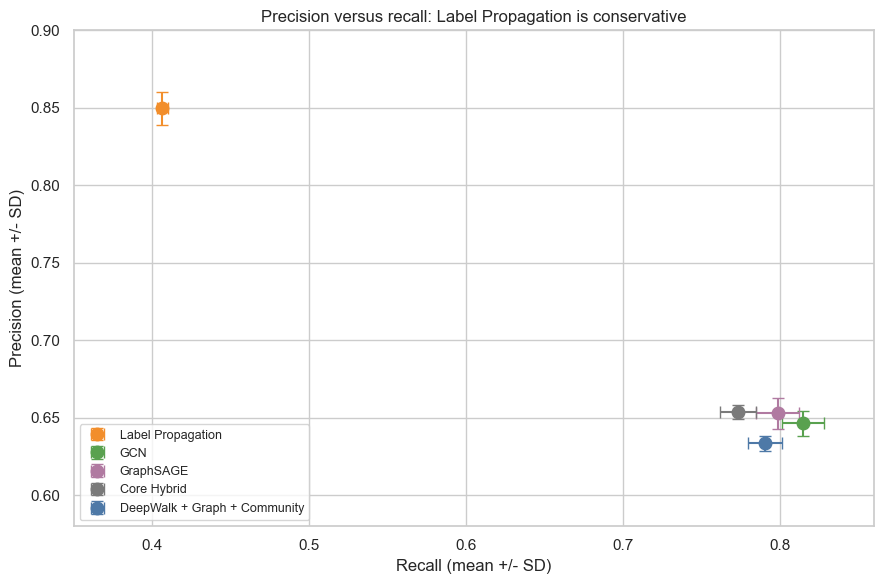

In [5]:
all_results = pd.concat([classification, core_results], ignore_index=True)
pr_summary = all_results.groupby('model').agg(
    precision_mean=('precision', 'mean'), precision_std=('precision', 'std'),
    recall_mean=('recall', 'mean'), recall_std=('recall', 'std'),
).loc[MODEL_ORDER].reset_index()
fig, ax = plt.subplots(figsize=(9, 6))
for _, row in pr_summary.iterrows():
    model = row['model']
    ax.errorbar(
        row['recall_mean'], row['precision_mean'],
        xerr=row['recall_std'], yerr=row['precision_std'],
        fmt='o', markersize=9, capsize=4, color=MODEL_COLORS[model],
        label=DISPLAY_NAMES[model],
    )
ax.set_xlabel('Recall (mean +/- SD)')
ax.set_ylabel('Precision (mean +/- SD)')
ax.set_xlim(0.35, 0.86)
ax.set_ylim(0.58, 0.90)
ax.set_title('Precision versus recall: Label Propagation is conservative')
ax.legend(loc='lower left', fontsize=9)
save_show(fig, 'label_propagation_precision_recall.png')

Label Propagation sits far above the other models in precision (0.850) but far left in recall (0.407): it predicts the ML class only when graph evidence is strong and misses many ML nodes. Its mean ROC-AUC is 0.8025 and Macro-F1 is 0.7218, so it is an interpretable graph-smoothing reference, not an improvement over the core models.

## Experiment 2 - Graph Convolutional Network (GCN)

The two-layer GCN applies symmetric normalized message passing with ReLU, dropout, and class-weighted cross-entropy. The charts below use seed 42 as the predeclared representative split and show the complete history of the validation-selected configuration. The vertical line is the stopping epoch selected by minimum validation loss; it is then used for a fresh outer-training refit.

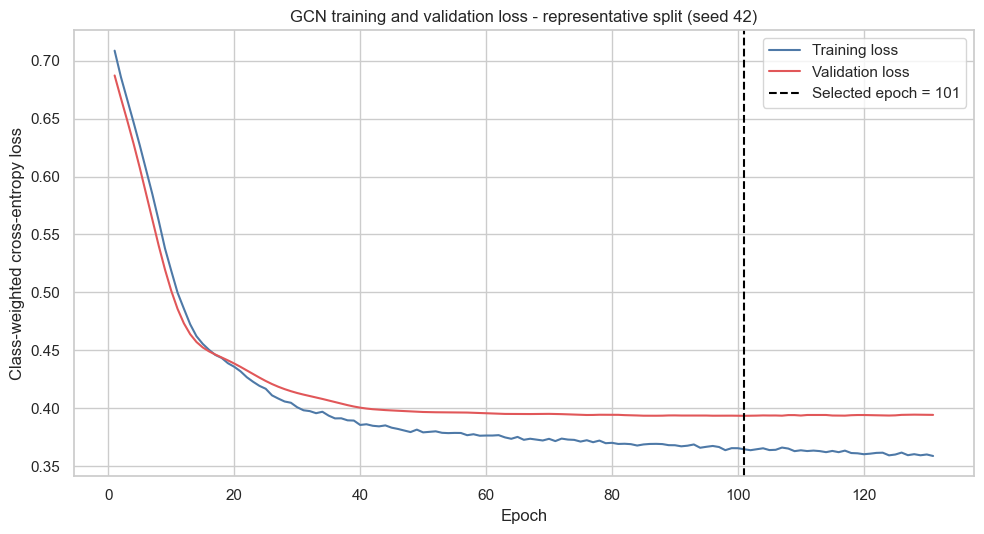

In [6]:
gcn_history_42 = gnn_history.query("model == 'GCN' and random_state == 42").copy()
gcn_stop = int(gcn_history_42['selected_epoch'].iloc[0])
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(gcn_history_42['epoch'], gcn_history_42['training_loss'], label='Training loss', color='#4E79A7')
ax.plot(gcn_history_42['epoch'], gcn_history_42['validation_loss'], label='Validation loss', color='#E15759')
ax.axvline(gcn_stop, color='black', linestyle='--', label=f'Selected epoch = {gcn_stop}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Class-weighted cross-entropy loss')
ax.set_title('GCN training and validation loss - representative split (seed 42)')
ax.legend()
save_show(fig, 'gcn_loss_history_seed42.png')

Both losses fall during training. Validation loss reaches its best value at epoch 101 and then stops improving for the patience window, so the final model does not use a test-selected epoch.

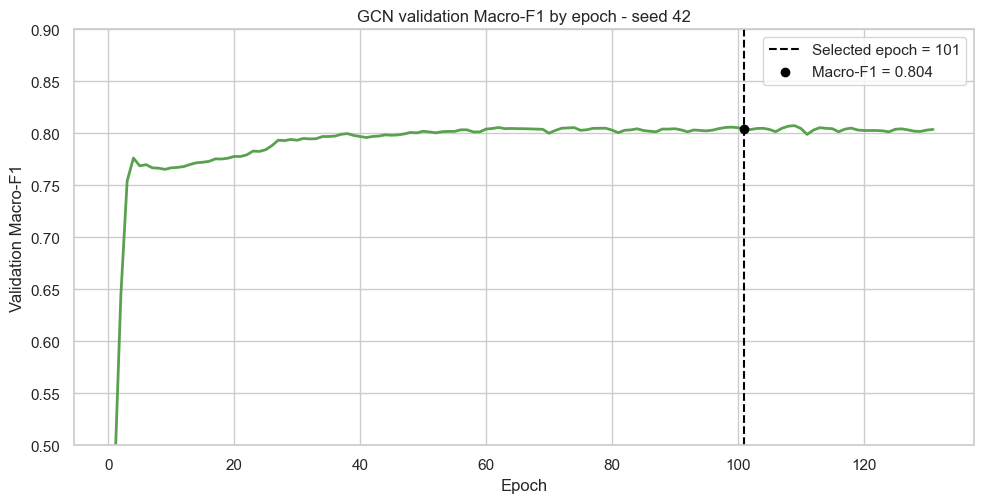

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(gcn_history_42['epoch'], gcn_history_42['validation_macro_f1'], color=MODEL_COLORS['GCN'], linewidth=2)
ax.axvline(gcn_stop, color='black', linestyle='--', label=f'Selected epoch = {gcn_stop}')
selected_gcn_f1 = gcn_history_42.loc[gcn_history_42['epoch'] == gcn_stop, 'validation_macro_f1'].iloc[0]
ax.scatter([gcn_stop], [selected_gcn_f1], color='black', zorder=3, label=f'Macro-F1 = {selected_gcn_f1:.3f}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation Macro-F1')
ax.set_ylim(0.5, 0.9)
ax.set_title('GCN validation Macro-F1 by epoch - seed 42')
ax.legend()
save_show(fig, 'gcn_validation_macro_f1_seed42.png')

Validation Macro-F1 rises quickly and then changes only slightly. The marked epoch is selected by validation loss, while the test set remains hidden.

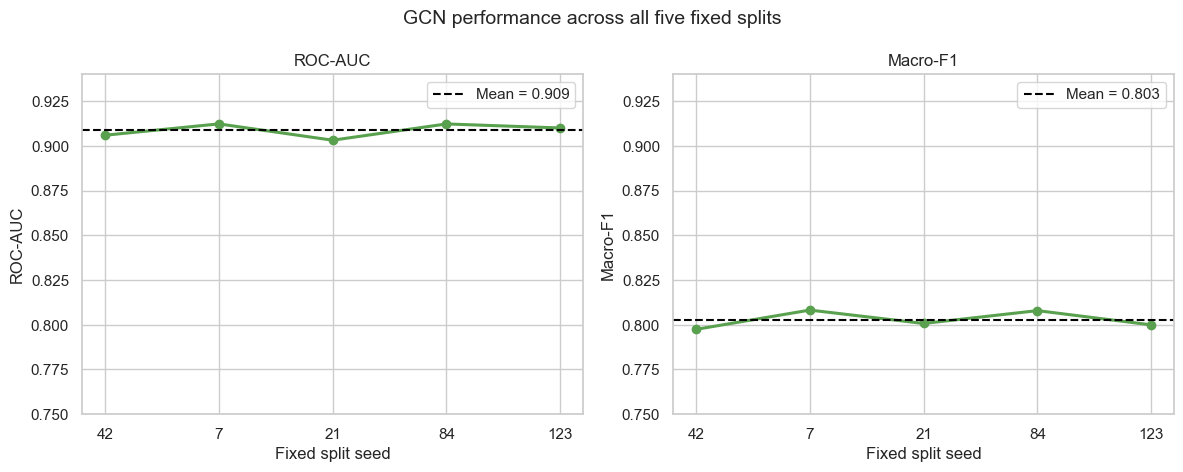

In [8]:
gcn_results = classification.query("model == 'GCN'").copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for ax, metric, title in zip(axes, ['roc_auc', 'macro_f1'], ['ROC-AUC', 'Macro-F1']):
    ax.plot(gcn_results['random_state'].astype(str), gcn_results[metric], marker='o', linewidth=2.2, color=MODEL_COLORS['GCN'])
    ax.axhline(gcn_results[metric].mean(), color='black', linestyle='--', label=f"Mean = {gcn_results[metric].mean():.3f}")
    ax.set_xlabel('Fixed split seed')
    ax.set_ylabel(title)
    ax.set_ylim(0.75, 0.94)
    ax.set_title(title)
    ax.legend()
fig.suptitle('GCN performance across all five fixed splits', fontsize=14)
save_show(fig, 'gcn_metrics_by_seed.png')

GCN is stable across the five splits: ROC-AUC is 0.9087 +/- 0.0040 and Macro-F1 is 0.8028 +/- 0.0049. It modestly improves the strongest core comparisons under this transductive protocol, but this is not evidence about unseen nodes.

## Experiment 3 - GraphSAGE

GraphSAGE concatenates each node's representation with the full-neighborhood mean before a learned transformation. It uses the same inputs, validation grid, fixed threshold, and final-refit rule as GCN. Although the architecture can support inductive use, this full-graph evaluation is transductive.

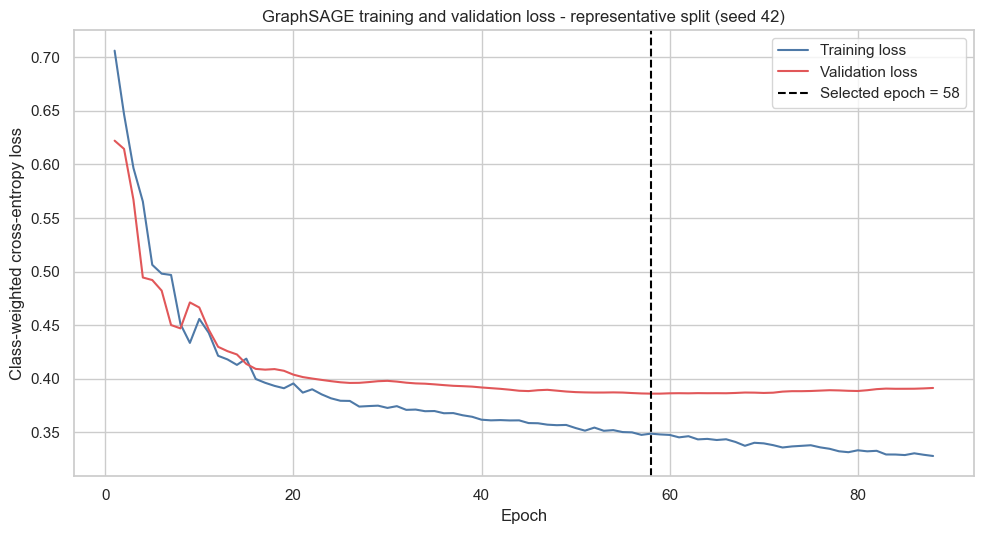

In [9]:
sage_history_42 = gnn_history.query("model == 'GraphSAGE' and random_state == 42").copy()
sage_stop = int(sage_history_42['selected_epoch'].iloc[0])
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(sage_history_42['epoch'], sage_history_42['training_loss'], label='Training loss', color='#4E79A7')
ax.plot(sage_history_42['epoch'], sage_history_42['validation_loss'], label='Validation loss', color='#E15759')
ax.axvline(sage_stop, color='black', linestyle='--', label=f'Selected epoch = {sage_stop}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Class-weighted cross-entropy loss')
ax.set_title('GraphSAGE training and validation loss - representative split (seed 42)')
ax.legend()
save_show(fig, 'graphsage_loss_history_seed42.png')

GraphSAGE training and validation losses both fall. Seed 42 selects epoch 58 from validation loss and then refits for exactly that many epochs using all outer-training labels.

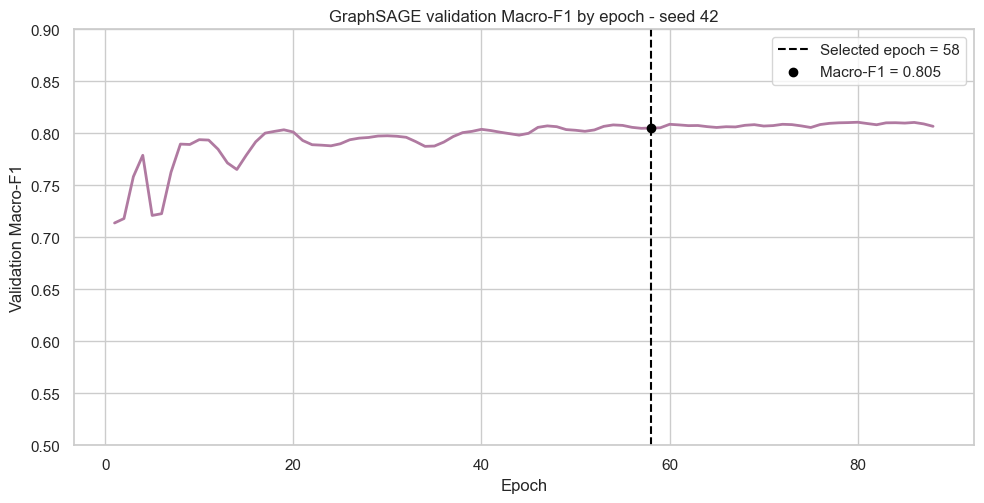

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(sage_history_42['epoch'], sage_history_42['validation_macro_f1'], color=MODEL_COLORS['GraphSAGE'], linewidth=2)
ax.axvline(sage_stop, color='black', linestyle='--', label=f'Selected epoch = {sage_stop}')
selected_sage_f1 = sage_history_42.loc[sage_history_42['epoch'] == sage_stop, 'validation_macro_f1'].iloc[0]
ax.scatter([sage_stop], [selected_sage_f1], color='black', zorder=3, label=f'Macro-F1 = {selected_sage_f1:.3f}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation Macro-F1')
ax.set_ylim(0.5, 0.9)
ax.set_title('GraphSAGE validation Macro-F1 by epoch - seed 42')
ax.legend()
save_show(fig, 'graphsage_validation_macro_f1_seed42.png')

Validation Macro-F1 reaches a stable region before early stopping. The selected point comes from validation behavior only; test labels do not influence this curve.

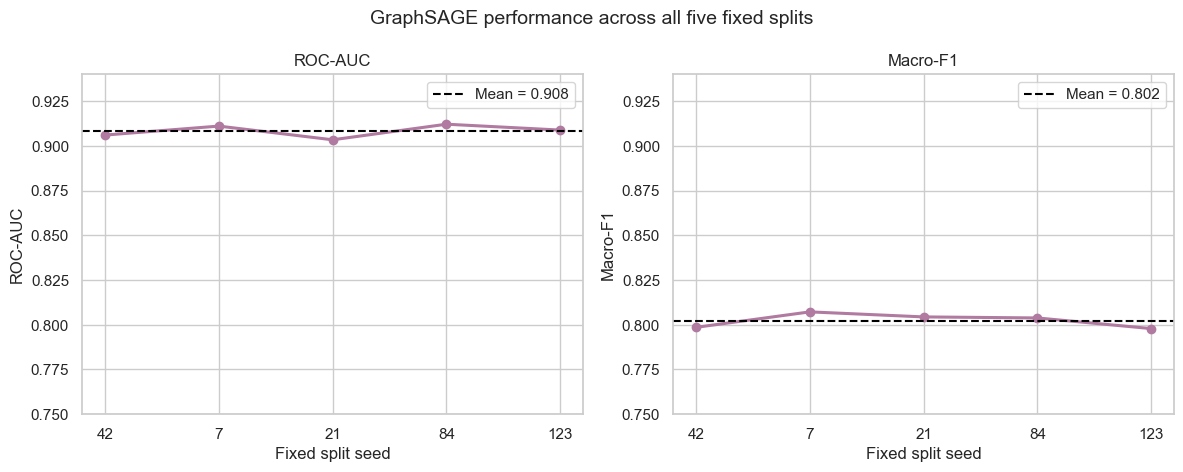

In [11]:
sage_results = classification.query("model == 'GraphSAGE'").copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True)
for ax, metric, title in zip(axes, ['roc_auc', 'macro_f1'], ['ROC-AUC', 'Macro-F1']):
    ax.plot(sage_results['random_state'].astype(str), sage_results[metric], marker='o', linewidth=2.2, color=MODEL_COLORS['GraphSAGE'])
    ax.axhline(sage_results[metric].mean(), color='black', linestyle='--', label=f"Mean = {sage_results[metric].mean():.3f}")
    ax.set_xlabel('Fixed split seed')
    ax.set_ylabel(title)
    ax.set_ylim(0.75, 0.94)
    ax.set_title(title)
    ax.legend()
fig.suptitle('GraphSAGE performance across all five fixed splits', fontsize=14)
save_show(fig, 'graphsage_metrics_by_seed.png')

GraphSAGE is also stable: ROC-AUC is 0.9083 +/- 0.0036 and Macro-F1 is 0.8024 +/- 0.0040. Its results are close to GCN, so this experiment does not establish a generally superior architecture.

## Fair model comparison

The core Hybrid is strongest in the saved core results by Macro-F1, while DeepWalk + Graph + Community is strongest by ROC-AUC. All models below use the same five outer test partitions and the same metric definitions. Representation budgets differ, so the result is a matched predictive comparison rather than an architecture-only ablation.

,Model,roc_auc,macro_f1,f1,balanced_accuracy,precision,recall
0,Label Propagation,0.8025 +/- 0.0092,0.7218 +/- 0.0024,0.5499 +/- 0.0039,0.6907 +/- 0.0020,0.8498 +/- 0.0106,0.4065 +/- 0.0037
1,GCN,0.9087 +/- 0.0040,0.8028 +/- 0.0049,0.7208 +/- 0.0070,0.8297 +/- 0.0059,0.6464 +/- 0.0079,0.8148 +/- 0.0132
2,GraphSAGE,0.9083 +/- 0.0036,0.8024 +/- 0.0040,0.7183 +/- 0.0054,0.8252 +/- 0.0047,0.6528 +/- 0.0098,0.7986 +/- 0.0137
3,Core Hybrid,0.8975 +/- 0.0041,0.7970 +/- 0.0047,0.7085 +/- 0.0073,0.8153 +/- 0.0059,0.6538 +/- 0.0046,0.7733 +/- 0.0114
4,DeepWalk + Graph + Community,0.8996 +/- 0.0047,0.7910 +/- 0.0040,0.7034 +/- 0.0060,0.8156 +/- 0.0051,0.6335 +/- 0.0050,0.7906 +/- 0.0106


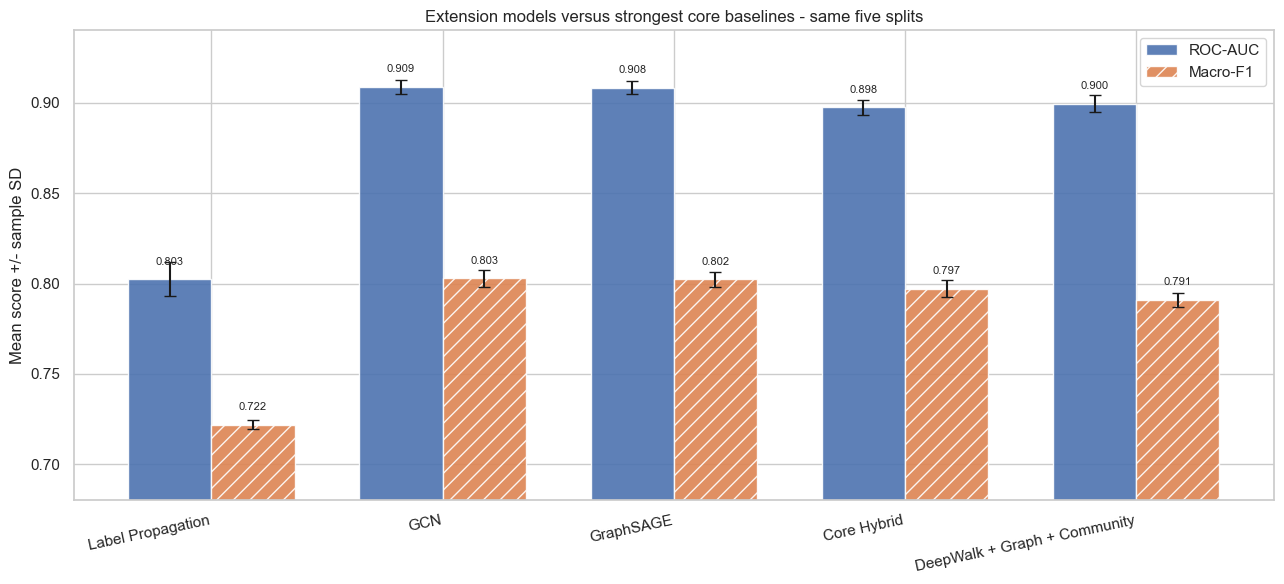

In [12]:
comparison_indexed = comparison_summary.set_index('model').loc[MODEL_ORDER]
display(mean_sd_table(comparison_indexed.reset_index()))
x = np.arange(len(MODEL_ORDER))
width = 0.36
fig, ax = plt.subplots(figsize=(13, 6))
for offset, metric, label, hatch in [
    (-width / 2, 'roc_auc', 'ROC-AUC', ''),
    (width / 2, 'macro_f1', 'Macro-F1', '//'),
]:
    means = comparison_indexed[f'{metric}_mean'].to_numpy()
    stds = comparison_indexed[f'{metric}_std'].to_numpy()
    bars = ax.bar(x + offset, means, width, yerr=stds, capsize=4, label=label, alpha=0.9, hatch=hatch)
    for bar, value in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, value + 0.008, f'{value:.3f}', ha='center', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([DISPLAY_NAMES[m] for m in MODEL_ORDER], rotation=12, ha='right')
ax.set_ylabel('Mean score +/- sample SD')
ax.set_ylim(0.68, 0.94)
ax.set_title('Extension models versus strongest core baselines - same five splits')
ax.legend()
save_show(fig, 'model_comparison_mean_sd.png')

GCN and GraphSAGE have the highest mean ROC-AUC and Macro-F1, but the gains are small. Label Propagation is clearly below the other four models on both measures. Error bars show that all five models are stable across the fixed splits.

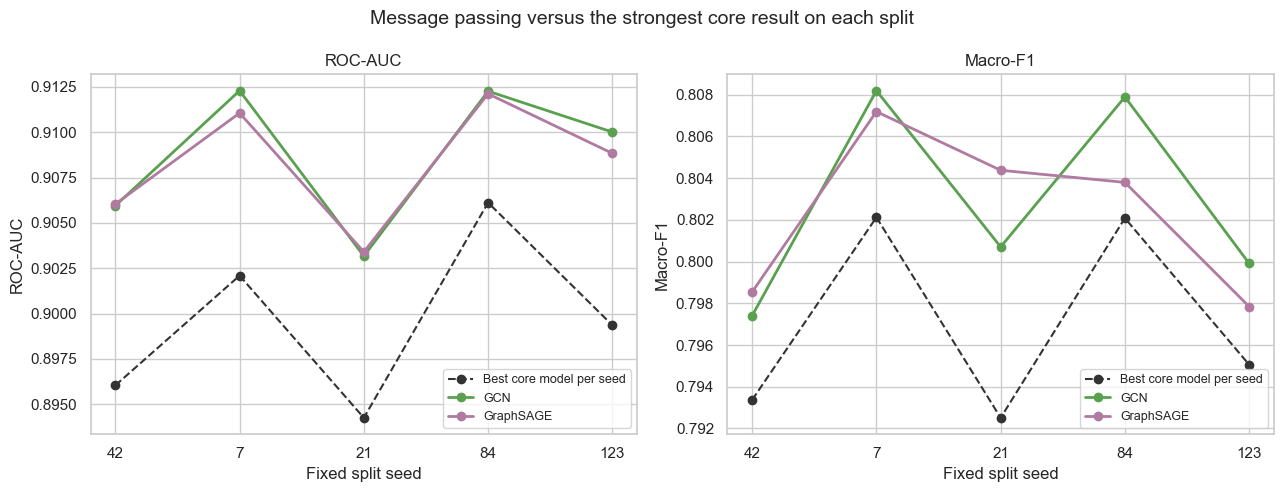

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, metric, title in zip(axes, ['roc_auc', 'macro_f1'], ['ROC-AUC', 'Macro-F1']):
    best_core = core_results.groupby('random_state')[metric].max().reindex(SEEDS)
    ax.plot([str(seed) for seed in SEEDS], best_core, marker='o', linestyle='--', color='#333333', label='Best core model per seed')
    for model in ['GCN', 'GraphSAGE']:
        values = classification.query('model == @model').set_index('random_state')[metric].reindex(SEEDS)
        ax.plot([str(seed) for seed in SEEDS], values, marker='o', linewidth=2, color=MODEL_COLORS[model], label=model)
    ax.set_xlabel('Fixed split seed')
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.legend(fontsize=9)
fig.suptitle('Message passing versus the strongest core result on each split', fontsize=14)
save_show(fig, 'message_passing_vs_best_core_by_seed.png')

For both ROC-AUC and Macro-F1, GCN and GraphSAGE are above the best of the two core comparators on every one of the five splits. This supports a small, consistent transductive gain on this graph; it does not show inductive performance or causal improvement.

## Experiment 4 - Content-subfield clustering

The 37,700 x 4,005 sparse content matrix is reduced to 64 L2-normalized TruncatedSVD components. K-means tests every `k=3..10`; selection maximizes silhouette on a fixed 5,000-node sample, while stability is pairwise adjusted Rand index across five K-means seeds with `n_init=10`. Binary labels are not used to fit clusters or select `k`. Feature indices are anonymous, so clusters are not given invented domain names.

,k,silhouette_fixed_sample,stability_ari_mean,stability_ari_std,smallest_cluster,largest_cluster
0,3,0.0494,1.0000,0.0000,7206,17128
1,4,0.0446,1.0000,0.0000,5526,13367
2,5,0.0442,0.9041,0.1238,5526,11602
3,6,0.0462,0.9333,0.0861,4133,11546
4,7,0.0442,0.4943,0.1544,3523,6767
5,8,0.0466,0.5305,0.1577,2946,8378
6,9,0.0469,0.6869,0.0800,3043,8053
7,10,0.0485,0.6183,0.2003,2699,5522


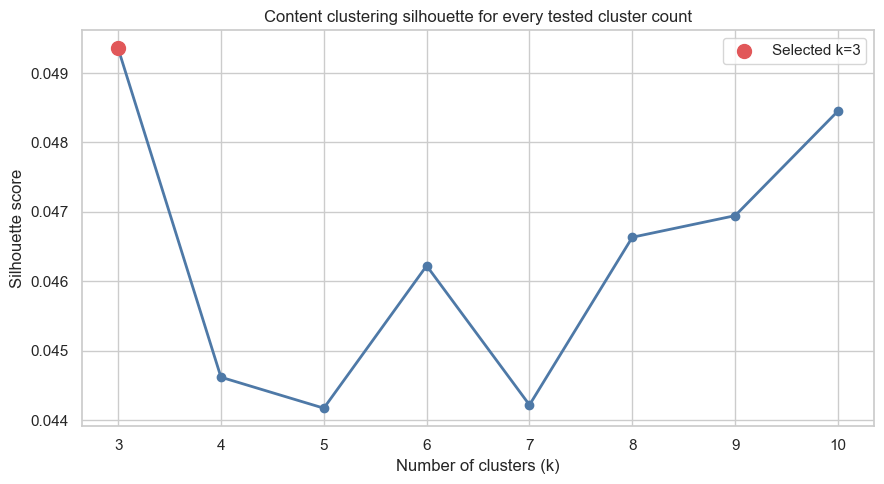

In [14]:
subfield_diagnostics = pd.read_csv(TABLES / 'subfield_k_diagnostics.csv')
subfield_sizes = pd.read_csv(TABLES / 'subfield_cluster_sizes.csv')
subfield_alignment = pd.read_csv(TABLES / 'subfield_alignment.csv')
stability_pairs = pd.read_csv(TABLES / 'subfield_stability_pairs.csv')
projection = pd.read_csv(TABLES / 'subfield_projection_sample.csv')
selected_k = int(subfield_meta['selected_k'])
display(subfield_diagnostics.round(4))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(subfield_diagnostics['k'], subfield_diagnostics['silhouette_fixed_sample'], marker='o', linewidth=2, color='#4E79A7')
selected_silhouette = subfield_diagnostics.loc[subfield_diagnostics['k'] == selected_k, 'silhouette_fixed_sample'].iloc[0]
ax.scatter([selected_k], [selected_silhouette], s=100, color='#E15759', zorder=3, label=f'Selected k={selected_k}')
ax.set_xticks(range(3, 11))
ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Silhouette score')
ax.set_title('Content clustering silhouette for every tested cluster count')
ax.legend()
save_show(fig, 'subfield_silhouette_by_k.png')

The target-free rule selects `k=3`, but its silhouette is only 0.0494. The groups are therefore weakly separated even though this is the best tested value.

,cluster,size,ml_count,share_of_nodes,ml_share
0,0,13366,3078,0.3545,0.2303
1,1,17128,4099,0.4543,0.2393
2,2,7206,2562,0.1911,0.3555


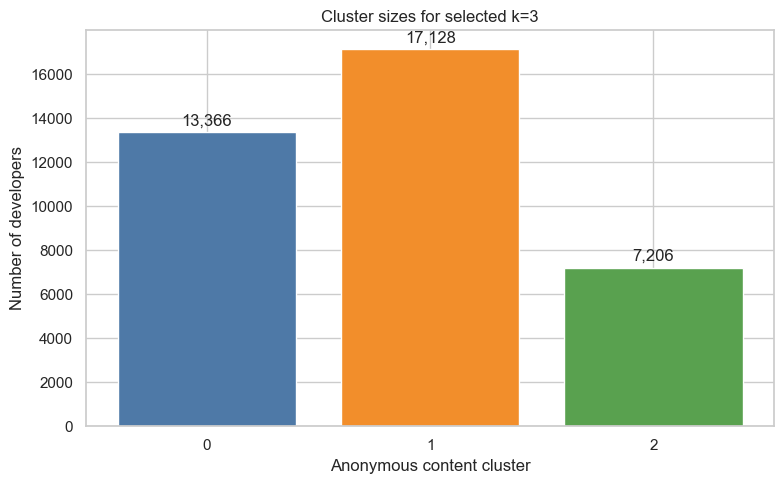

In [15]:
display(subfield_sizes.round(4))
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(subfield_sizes['cluster'].astype(str), subfield_sizes['size'], color=['#4E79A7', '#F28E2B', '#59A14F'])
for bar, size in zip(bars, subfield_sizes['size']):
    ax.text(bar.get_x() + bar.get_width()/2, size + 300, f'{int(size):,}', ha='center')
ax.set_xlabel('Anonymous content cluster')
ax.set_ylabel('Number of developers')
ax.set_title(f'Cluster sizes for selected k={selected_k}')
save_show(fig, 'subfield_cluster_sizes_selected_k.png')

The selected partition contains 13,366, 17,128, and 7,206 developers. No cluster is tiny, but unequal sizes alone do not provide a semantic meaning.

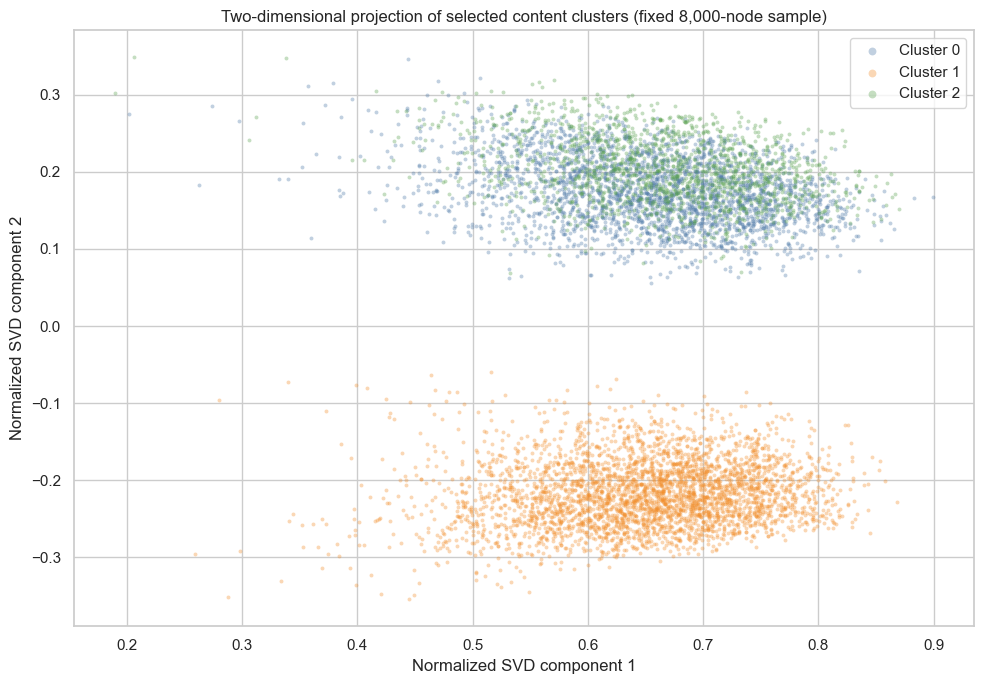

In [16]:
fig, ax = plt.subplots(figsize=(10, 7))
palette = {0: '#4E79A7', 1: '#F28E2B', 2: '#59A14F'}
for cluster in sorted(projection['content_cluster'].unique()):
    points = projection[projection['content_cluster'] == cluster]
    ax.scatter(points['svd_component_1'], points['svd_component_2'], s=8, alpha=0.35, color=palette[int(cluster)], label=f'Cluster {int(cluster)}', linewidths=0)
ax.set_xlabel('Normalized SVD component 1')
ax.set_ylabel('Normalized SVD component 2')
ax.set_title('Two-dimensional projection of selected content clusters (fixed 8,000-node sample)')
ax.legend(markerscale=2)
save_show(fig, 'subfield_projection_2d.png')

Cluster 1 separates along the second component, while clusters 0 and 2 overlap strongly. This two-dimensional view is descriptive and does not justify naming any anonymous cluster.

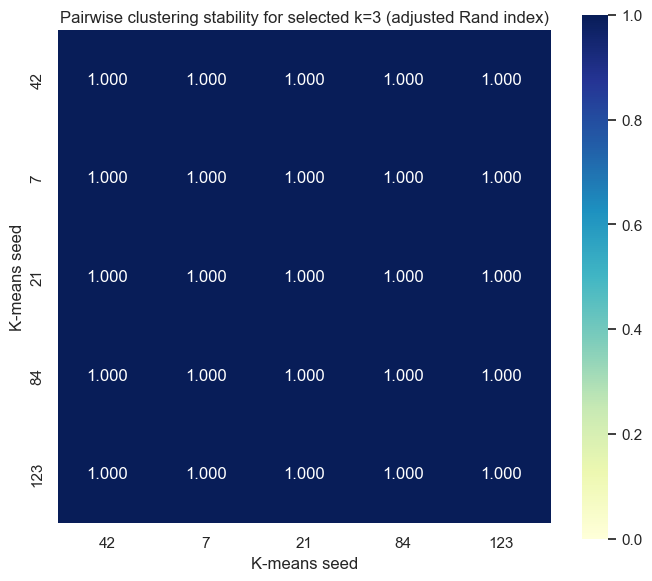

,comparison,nmi,ari
0,content_clusters_vs_binary_labels,0.0069,0.0181
1,content_clusters_vs_louvain_communities,0.0079,0.0019
2,louvain_communities_vs_binary_labels,0.1061,0.0623


In [17]:
selected_stability = stability_pairs.query('k == @selected_k')
stability_matrix = pd.DataFrame(np.eye(len(SEEDS)), index=SEEDS, columns=SEEDS)
for _, row in selected_stability.iterrows():
    first, second = int(row['seed_a']), int(row['seed_b'])
    stability_matrix.loc[first, second] = row['adjusted_rand']
    stability_matrix.loc[second, first] = row['adjusted_rand']
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(stability_matrix, annot=True, fmt='.3f', vmin=0, vmax=1, cmap='YlGnBu', square=True, ax=ax)
ax.set_xlabel('K-means seed')
ax.set_ylabel('K-means seed')
ax.set_title(f'Pairwise clustering stability for selected k={selected_k} (adjusted Rand index)')
save_show(fig, 'subfield_stability_heatmap.png')
display(subfield_alignment.round(4))

Every seed pair has ARI 1.000 for `k=3`, so the coarse solution is exactly stable across the tested initializations. Stability does not fix weak separation: agreement with binary labels is also very low (NMI 0.0069, ARI 0.0181). The supported conclusion is a reproducible coarse partition in the reduced feature geometry, not distinct or interpretable professional subfields.

## Combined extension conclusion

Label Propagation adds a transparent but conservative graph-smoothing baseline and does not improve the core results. GCN and GraphSAGE add learned message passing and produce small, consistent gains over the strongest saved core comparisons on the same five splits. Content clustering adds a stable coarse view of content geometry, but low silhouette and anonymous features prevent strong semantic interpretation.

The evidence is limited to this static graph and transductive setting. It does not support unseen-node, future-graph, causal, or inductive claims. Other limitations are the small GNN grid, five split seeds, shared graph topology, and 64-component content reduction retaining about 55.9% of variance.